# Exercise Sheet 1 (unsolved)
*Machine Learning for Data Science, Winter Semester 2026/27 — Prof. Dr.-Ing. Gerhard Wunder, Freie Universität Berlin*

In the following, we explore different ways of accessing data, including reading CSV files, querying databases, and applying preprocessing and plotting techniques to the available data. The cell below imports some libraries that are required to complete the tasks. Note that you need to install additional python libraries such as `cv2`, `torch`, `torchvision`, `matplotlib` and `sqlite3`. Some of these libraries will also be needed for the next exercise sheets.

In [1]:
%matplotlib inline
import numpy,scipy,scipy.spatial
import torch
import torchvision,torchvision.transforms
import sqlite3
import matplotlib
from matplotlib import pyplot as plt
from PIL import Image

## Exercise 1: Loading CSV Data (15+15 P)

In this exercise, we investigate the usage of the function `numpy.genfromtxt` to load several datasets from the UCI repository. These datasets are provided in the form of csv files in the folder `csvdata` of the homework.

**(a)** Using the method `numpy.genfromtxt`, load the dataset contained in the file `Wholesale customers data.csv`. In this dataset, instances (rows) are retailers, and features (columns) represent how much these retailers spend for different categories of products. Once the dataset is loaded, compute the average and median spending (over instances) for each category of products.

In [2]:
wholesale_dataset = numpy.genfromtxt('csvdata/Wholesale customers data.csv', delimiter=',', names=True)
for field in sorted(wholesale_dataset.dtype.names):
    col = wholesale_dataset[field]
    print(f"{field:20s} {col.mean():10.3f} {numpy.median(col):10.3f}")

Channel                   1.323      1.000
Delicassen             1524.870    965.500
Detergents_Paper       2881.493    816.500
Fresh                 12000.298   8504.000
Frozen                 3071.932   1526.000
Grocery                7951.277   4755.500
Milk                   5796.266   3627.000
Region                    2.543      3.000


Expected output:
```
Fresh                 12000.298   8504.000
Milk                   5796.266   3627.000
Grocery                7951.277   4755.500
Frozen                 3071.932   1526.000
Detergents_Paper       2881.493    816.500
Delicatessen           1524.870    965.500
```

**(b)** Using the method `numpy.genfromtxt`, load the dataset contained in the file `CortexNuclear.csv`, and use the library `matplotlib` to produce an image plot that visualizes the dataset, specifically visualize the first 30 instances that do not contain any missing value.

In [3]:
#TODO: I would prob need help here as numpy.genfromtxt is really barebones and seems like cannot process strings
cortex_nuclear = numpy.genfromtxt('csvdata/CortexNuclear.csv', delimiter=',', names=True, encoding='utf-8',dtype=float)
names = cortex_nuclear.dtype.names

data = numpy.column_stack([cortex_nuclear[n] for n in names])

complete = data[~numpy.isnan(data).any(axis=1)]

print(complete)

[]


## Exercise 2: Querying a Database (20+20 P)

In the following, we will use the sqlite3 package to connect to a database, and perform various join operations. The sqlite3 package enables you to connect to a database and to perform various queries. We will consider the chinook database, which simulates data from a music store, relating music tracks, artists, invoices, customers, etc. Connect to the database. The database can also be downloaded from the link https://www.sqlitetutorial.net/sqlite-sample-database/.

In [4]:
db = sqlite3.connect('chinook.db')

We first consider a simple query on this database. The query is formulated in the SQL language and retrieves the duration of tracks found in that database. Once the results of the query have been obtained, we perform a very basic data analysis: computing the mean track duration.

In [5]:
cursor = db.cursor()
query = "SELECT Milliseconds FROM tracks;"
results = numpy.array(cursor.execute(query).fetchall())
mean = results.mean()/1000.0
print(f"{'Average track duration':25s} {mean:8.3f}")

Average track duration     393.599


Now, we would like to perform more complex SQL queries. For a tutorial on SQL, see for example, https://www.sqltutorial.org/. In particular, look at Section 6 which discusses the SQL operation "INNER JOIN" and that is useful for generating outputs involving multiple tables.

**(a)** Apply a SQL query that extracts a table containing for all tracks their genre and their track length. Then, write code that computes for each genre (sorted alphabetically) the average track length.

In [6]:
query_avg_track_len = """
SELECT 
	genres.Name,
	ROUND(AVG(tracks.Milliseconds / 1000.0), 3) as AvgGenreLength
FROM
	tracks
	INNER JOIN genres
	on genres.GenreId = tracks.GenreId
GROUP BY
	genres.Name
ORDER BY
	genres.Name;
"""

result_avg_track_len = cursor.execute(query_avg_track_len).fetchall()
for genre, len_s in result_avg_track_len:
    print(f"{genre:20s} {len_s}")

Alternative          264.059
Alternative & Punk   234.354
Blues                270.36
Bossa Nova           219.59
Classical            293.868
Comedy               1585.264
Drama                2575.284
Easy Listening       189.164
Electronica/Dance    302.986
Heavy Metal          297.453
Hip Hop/Rap          178.176
Jazz                 291.755
Latin                232.859
Metal                309.749
Opera                174.813
Pop                  229.034
R&B/Soul             220.067
Reggae               247.178
Rock                 283.91
Rock And Roll        134.643
Sci Fi & Fantasy     2911.783
Science Fiction      2625.549
Soundtrack           244.371
TV Shows             2145.041
World                224.924


Expected output:
```
Alternative           264.059
Alternative & Punk    234.354
Blues                 270.360
Bossa Nova            219.590
Classical             293.868
Comedy               1585.264
Drama                2575.284
Easy Listening        189.164
Electronica/Dance     302.986
Heavy Metal           297.453
Hip Hop/Rap           178.176
Jazz                  291.755
Latin                 232.859
Metal                 309.749
Opera                 174.813
Pop                   229.034
R&B/Soul              220.067
Reggae                247.178
Rock                  283.910
Rock And Roll         134.644
Sci Fi & Fantasy     2911.783
Science Fiction      2625.549
Soundtrack            244.371
TV Shows             2145.041
World                 224.924
```

We would like to analyze the preference for music genres in different countries.

**(b)** Apply a SQL query that extracts for each invoice the country of the customer and the genre of the track the customer has purchased. Then, print in the form of a table the number of purchases for each country and genre.

In [7]:
import pandas as pd

query_country_genre = """
SELECT 
	customers.Country,
	genres.Name,
	COUNT(*) AS TrackCount
FROM
	invoices
	INNER JOIN invoice_items on invoices.InvoiceId = invoice_items.InvoiceId
	INNER JOIN customers on invoices.CustomerId = customers.CustomerId
	INNER JOIN tracks on invoice_items.TrackId = tracks.TrackId
	INNER JOIN genres on tracks.GenreId = genres.GenreId
GROUP BY customers.Country, genres.Name
ORDER BY customers.Country, genres.Name;
"""
result_country_genre = cursor.execute(query_country_genre).fetchall()
df_country_genre = pd.DataFrame(
    [tuple([c[:3], *rest]) for c, *rest in result_country_genre], columns=["Country", "Genre", "Count"]
)
print(df_country_genre.pivot_table(index="Genre", columns="Country", values="Count", fill_value=0, aggfunc=sum))

Country             Arg  Aus  Bel  Bra  Can  Chi  Cze  Den  Fin  Fra  ...  \
Genre                                                                 ...   
Alternative           0    0    0    0    0    0    0    0    0    4  ...   
Alternative & Punk    9    0   14    7   36    2    9    4    2   31  ...   
Blues                 0    1    0    6    4    2    1    0    0    2  ...   
Bossa Nova            0    0    0    0    7    0    0    0    0    1  ...   
Classical             0    2    0    6    5    1    0    0    0   10  ...   
Comedy                0    0    0    0    0    0    0    0    0    0  ...   
Drama                 0    1    0    0    2    4    6    0    0    4  ...   
Easy Listening        2    0    0    0    0    3    0    0    0    0  ...   
Electronica/Dance     0    0    0    0    4    0    2    0    0    2  ...   
Heavy Metal           0    3    0    0    0    0    0    0    0    0  ...   
Hip Hop/Rap           0    0    0    2    5    0    0    0    0    2  ...   

Expected output:
```
               ArgAusAusBelBraCanChiCzeDenFinFraGerHunIndIreItaNetNorPolPorSpaSweUSAUni
Alternative      0  0  0  0  0  0  0  0  0  0  4  1  0  0  0  0  0  4  0  0  0  0  5  0
Alternative & P  9  0  0 14  7 36  2  9  4  2 31 13  3 11  4 11  5  2  7  5  4  6 50  9
Blues            0  1  0  0  6  4  2  1  0  0  2 14  2  3  1  4  4  0  1  1  0  0 15  0
Bossa Nova       0  0  0  0  0  7  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  7  0
Classical        0  0  2  0  6  5  1  0  0  0 10  0  0  2  0  2  0  5  0  0  0  0  8  0
Comedy           0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  8  0
Drama            0  0  1  0  0  2  4  6  0  0  4  1  2  0  1  0  0  2  0  0  0  0  6  0
Easy Listening   2  0  0  0  0  0  3  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0  3  0
Electronica/Dan  0  0  0  0  0  4  0  2  0  0  2  0  1  0  0  0  0  2  0  1  0  0  0  0
Heavy Metal      0  3  0  0  0  0  0  0  0  0  0  3  0  0  0  0  0  0  0  2  0  0  4  0
Hip Hop/Rap      0  0  0  0  2  5  0  0  0  0  2  0  0  0  0  0  0  0  0  0  1  0  4  3
Jazz             2  0  2  0  0 13  0  3  0  2 11  2  0 10  3  0  0  0  1  2  2  1 22  4
Latin            8  2  2  0 53 60  8  9  4  9 26 18  3  9  7  2  3  5  7 13  4 12 91 31
Metal            7  8  7  1 15 40  3  6  6  2 20 25  5  8  3  1  2  0  0 11  3  7 64 20
Pop              0  0  1  0  3  0  0  4  3  0  2  1  0  0  0  0  3  0  0  4  0  0  5  2
R&B/Soul         0  0  4  2  3  5  0  2  0  0  0  0  5  4  0  0  0  0  0  2  0  0 12  2
Reggae           0  2  0  0  6  7  0  0  0  1  1  0  0  0  0  0  0  0  0  0  2  0  6  5
Rock             9 22 15 21 81107  9 25 21 18 65 62 11 25 12 18 18 17 22 31 22 10157 37
Rock And Roll    0  0  0  0  0  2  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  3  0
Sci Fi & Fantas  0  0  0  0  2  0  1  0  0  4  2  0  1  1  0  0  3  0  0  1  0  0  5  0
Science Fiction  0  0  0  0  0  0  2  1  0  0  0  2  0  0  0  0  0  0  0  0  0  0  1  0
Soundtrack       1  0  0  0  4  0  1  0  0  0  5  5  0  0  0  0  0  0  0  0  0  0  4  0
TV Shows         0  0  4  0  0  1  2  8  0  0  1  3  4  1  7  0  0  0  0  1  0  1 14  0
World            0  0  0  0  2  6  0  0  0  0  0  0  0  0  0  0  0  1  0  2  0  1  0  1
```

## Exercise 3: Representing Images (15+15 P)

Images are high-dimensional data. High-level concepts contained in these images are hard to extract directly from the raw pixel representation. In the following, we investigate the benefit of preprocessing the data with a neural network. Specifically, we want to see if representations built by the neural network enable to produce meaningful similarities or dissimilarities between images. We consider for this exercise a set of 10 images. The first 5 images depict geraniums, and the last 5 images depict ferrari cars.

In [8]:
images = [Image.open(f'imagedata/{i}.jpg') for i in range(10)]

Although the two groups are clearly distinct from a human point of view, we will show that distances computed on pixel values (i.e. treating an image as vector storing the multiple RGB pixel values) does not enable such distinction.

**(a)** Compute a matrix of pairwise Euclidean distances between images (images are resized to 100 x 100 for this task).

In [9]:
resizedimages = [numpy.array(img.resize((100,100))).flatten() for img in images]
np_resizedimages = numpy.array(resizedimages).astype(numpy.int32)
np_resizedimages.shape

(10, 30000)

The distance matrix can then be displayed using `matplotlib`.

In [10]:
n = len(np_resizedimages)
D = numpy.zeros((n,n))
for i in range(n):
    for j in range(i + 1, n):
        d = numpy.sqrt(numpy.sum((np_resizedimages[i] - np_resizedimages[j]) ** 2))
        D[i, j] = d
        D[j, i] = d

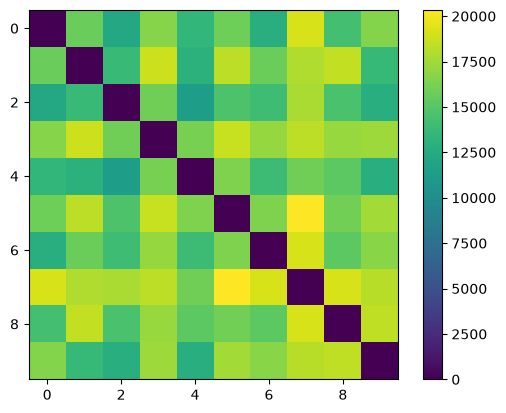

In [11]:
plt.imshow(D)
plt.colorbar()

We cannot see clear similarities (low distances) within each image group. This suggests that the pixel representation does not encode well the concepts we are interested in.

To address this limitation, we consider a state-of-the-art neural network called `densenet161` and available pretrained in the `torchvision` library. This neural network is composed of a feature extractor and a classification head. The feature extractor transforms image data (given as a `torch` tensor) into a tensor of activations where concepts are easier to predict.

**(b)** Compute the distance matrix between the images represented at the output of the densenet features extractor.

*Hints:* (1) The input images need to be converted to a torch tensor and then normalized using the function provided below before being fed to the neural network. (2) Note that the tensor at the output of the network can vary in shape due to the varying size of the input images. This can be addressed by applying the mean operation over the two dimensions representing the horizontal and vertical components.

/home/max/Documents/MAIN/fu_ds/1 sem/ML for DS/Exercises/.venv/lib/python3.13/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/max/Documents/MAIN/fu_ds/1 sem/ML for DS/Exercises/.venv/lib/python3.13/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet161_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet161_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


torch.Size([10, 2208, 3, 3])


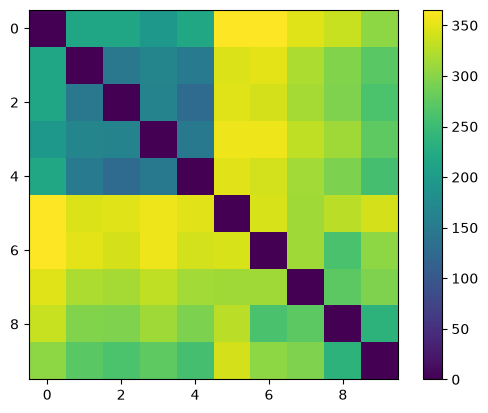

In [12]:
model = torchvision.models.densenet161(pretrained=True).features
model.eval();

def normalize(x):
    x = x - torch.Tensor([0.485, 0.456, 0.406]).reshape(1,-1,1,1)
    x = x / torch.Tensor([0.229, 0.224, 0.225]).reshape(1,-1,1,1)
    return x

with torch.no_grad():
    x = torch.tensor(np_resizedimages) / 255
    x = x.reshape(10, 100, 100, 3).permute(0, 3, 1, 2)
    features = model(normalize(x))
    print(features.shape)
    features = features.numpy() 

D = numpy.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        d = numpy.sqrt(numpy.sum((features[i] - features[j]) ** 2))
        D[i, j] = d
        D[j, i] = d

plt.imshow(D)
plt.colorbar()

We observe that distances now form a block structure, where the first 5 images are clearly mutually similar, and similarly for the last 5 images.